# TS7 — Filtrado digital lineal de ECG

## Análisis y Procesamiento de Señales

### Integrantes: Catalina Wynne - Aylin Cano - Bernardita Aragón

## Introducción

En este trabajo práctico se propone diseñar y aplicar filtros digitales lineales sobre una señal electrocardiográfica (ECG) registrada durante una prueba de esfuerzo, con el objetivo de reducir las interferencias presentes y mejorar la calidad de la señal.

El registro contiene principalmente tres fuentes de contaminación: ruido asociado al movimiento de los electrodos, ruido muscular y desplazamientos de la línea de base, estos últimos relacionados, en parte, con la respiración.

Para reducir estas interferencias se diseñarán filtros pasabanda, capaces de atenuar tanto las componentes de muy baja frecuencia como las de alta frecuencia, procurando conservar la información útil del ECG.

Se trabajará con filtros de respuesta finita al impulso (FIR), utilizando las metodologías de ventanas, cuadrados mínimos y Parks-McClellan-Remez, y con filtros de respuesta infinita al impulso (IIR), mediante las aproximaciones Butterworth, Chebyshev tipo I y Cauer.

Finalmente, se compararán sus respuestas en frecuencia y sus resultados sobre diferentes regiones del ECG, evaluando tanto su capacidad para reducir las interferencias como las posibles modificaciones introducidas en la morfología de los latidos.

In [1]:
# 0. IMPORTACIÓN DE MÓDULOS
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sig
import scipy.io as sio

## 1. Carga y visualización de la señal ECG

In [2]:
# 1. CARGA DEL ECG
fs = 1000  # Hz: frecuencia de muestreo del registro

# El archivo ECG_TP4.mat debe encontrarse en la carpeta de trabajo.
mat_struct = sio.loadmat('pdstestbench/ECG_TP4.mat')
ecg_conruido = mat_struct['ecg_lead'].flatten()
t_ecg = np.arange(len(ecg_conruido)) / fs

print('Cantidad de muestras del ECG:', len(ecg_conruido))
print('Duración del ECG:', len(ecg_conruido) / fs, 'segundos')


Cantidad de muestras del ECG: 1129116
Duración del ECG: 1129.116 segundos


### 1.1. Visualización del ECG original

Para realizar una primera visualizacion de la señal, se representan los primeros 10 segundos del registro.

Se selecciona este intervalo para observar con mayor claridad los latidos y las variaciones de amplitud. Esta visualización inicial permite reconocer la morfología general del ECG y establecer una referencia para comparar posteriormente los resultados obtenidos mediante los distintos filtros digitales.

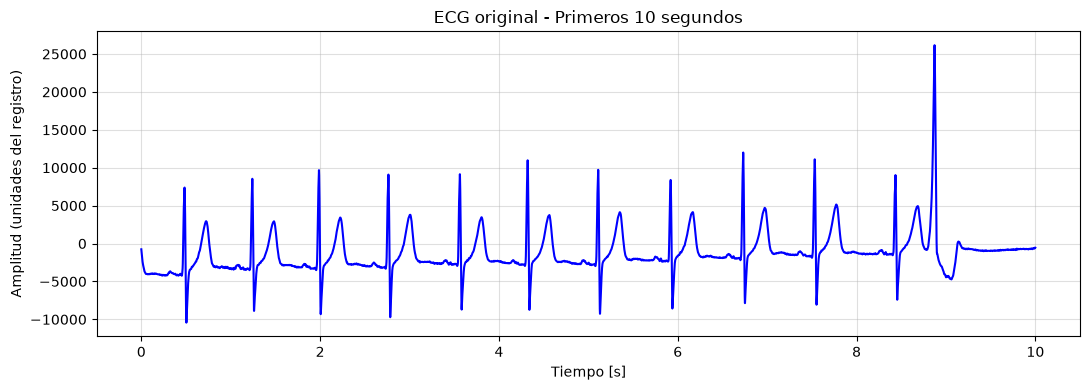

In [3]:
# 1.1. PRIMERA VISUALIZACIÓN DEL ECG SIN FILTRAR
plt.figure(figsize=(11, 4))
plt.plot(t_ecg[:10*fs], ecg_conruido[:10*fs], color='blue')
plt.title('ECG original - Primeros 10 segundos')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud (unidades del registro)')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

### 1.2. Análisis de la señal original

En la representación de los primeros 10 segundos del ECG se pueden identificar los complejos QRS, caracterizados por picos pronunciados, y ondas de evolución más lenta que aparecen entre los latidos.

También se observan variaciones en el nivel de la línea de base, que no permanece constante en cero, así como pequeñas fluctuaciones superpuestas a la señal.

Hacia el final del intervalo, aproximadamente a los 9 segundos, aparece una variación de amplitud considerablemente mayor que la de los latidos anteriores. Este comportamiento evidencia la presencia de alteraciones que deberán tenerse en cuenta durante la evaluación del filtrado.

Por lo tanto, el objetivo será reducir las componentes interferentes y corregir el desplazamiento de la línea de base, procurando conservar la morfología de los latidos.

## 2. Plantilla de diseño de los filtros digitales

### 2.1. Selección del tipo de filtro
Para abordar este problema se decidió utilizar **filtros pasabanda**, ya que el registro presenta interferencias en dos regiones del espectro:

- **Bajas frecuencias:** asociadas al desplazamiento de la línea de base, inducido en parte por la respiración.
- **Altas frecuencias:** asociadas al ruido muscular y al movimiento de los electrodos, según las fuentes de contaminación indicadas en la consigna.

Un filtro pasabanda permite atenuar ambos extremos del espectro y conservar una región intermedia de frecuencias donde se concentra buena parte de la información útil del ECG.

Para establecer los límites de esta región se utilizaron como referencia los resultados obtenidos en la **Tarea Semanal 5**, en la que se estimó un ancho de banda del ECG de aproximadamente 30,6 Hz, considerando el 99 % de la potencia espectral.

A partir de este resultado se definió una plantilla con bandas de paso, rechazo y transición, que servirá como referencia común para diseñar y comparar los filtros FIR e IIR.

In [4]:
# 2. PLANTILLA DE DISEÑO - INCISOS A Y B
nyq_frec = fs / 2
ripple = 1       # dB: pérdida máxima admitida en la banda de paso
atenuacion = 40  # dB: atenuación mínima en rechazo

ws1 = 0.1  # Hz: fin del rechazo inferior
wp1 = 2.0  # Hz: comienzo de paso
wp2 = 35   # Hz: final de paso
ws2 = 45   # Hz: comienzo del rechazo superior

# Plantilla normalizada
frecs = np.array([0, ws1, wp1, wp2, ws2, nyq_frec]) / nyq_frec
gains_db = np.array([-atenuacion, -atenuacion,
                     -ripple, -ripple,
                     -atenuacion, -atenuacion])
gains = 10**(gains_db / 20)  # dB a amplitud lineal


In [35]:

# 2.1 VECTOR DE FRECUENCIAS PARA EVALUAR LOS FILTROS
# Las funciones firwin2, firls, remez e iirdesign reciben
# las frecuencias en Hz porque especificamos fs=fs.

# Construimos un vector de frecuencias común a los seis filtros.
# Incluimos más puntos en bajas frecuencias porque queremos analizar con detalle la transición inferior.

ww = np.concatenate([
    np.linspace(0, ws1, 200),
    np.linspace(ws1, wp1, 400),
    np.linspace(wp1, wp2, 500),
    np.linspace(wp2, ws2, 200),
    np.linspace(ws2, nyq_frec, 300)
])


### 2.2. Representación gráfica de la plantilla

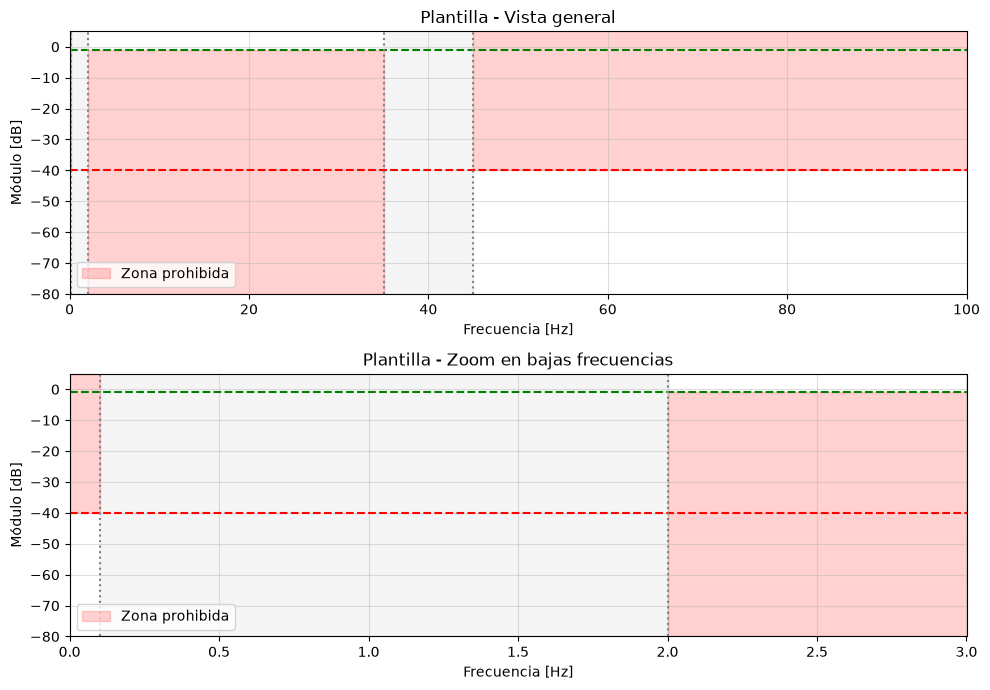

In [6]:
# 2.2. VISUALIZACIÓN DE LA PLANTILLA (GENERAL Y ZOOM)
fig, axs = plt.subplots(2, 1, figsize=(10, 7))
for ax, limite, titulo in zip(
        axs, [100, 3],
        ['Plantilla - Vista general', 'Plantilla - Zoom en bajas frecuencias']):

    # Zonas de ganancia no admitida en rechazo y paso.
    ax.fill_between([0, ws1], -atenuacion, 5,
                    color='red', alpha=0.18)
    ax.fill_between([wp1, wp2], -80, -ripple,
                    color='red', alpha=0.18, label='Zona prohibida')
    ax.fill_between([ws2, nyq_frec], -atenuacion, 5,
                    color='red', alpha=0.18)
    # Regiones de transición: el enunciado no impone ganancia exacta.
    ax.fill_between([ws1, wp1], -80, 5,
                    color='gray', alpha=0.08)
    ax.fill_between([wp2, ws2], -80, 5,
                    color='gray', alpha=0.08)
    ax.axhline(-ripple, color='green', linestyle='--')
    ax.axhline(-atenuacion, color='red', linestyle='--')
    for f_lim in [ws1, wp1, wp2, ws2]:
        ax.axvline(f_lim, color='gray', linestyle=':')
    ax.set_xlim(0, limite)
    ax.set_ylim(-80, 5)
    ax.set_title(titulo)
    ax.set_xlabel('Frecuencia [Hz]')
    ax.set_ylabel('Módulo [dB]')
    ax.grid(True, alpha=0.4)
    ax.legend(loc='lower left')
plt.tight_layout()
plt.show()

### 2.3. Justificación de los parámetros

Para definir la plantilla se consideraron las interferencias presentes en el ECG y los resultados de la **TS5**, donde se estimó un ancho de banda de aproximadamente **30,6 Hz**, que contenía el 99 % de la potencia espectral.

Se establecieron las siguientes frecuencias:
- **ws1 = 0,1 Hz:** delimita el rechazo de las componentes de muy baja frecuencia asociadas al desplazamiento de la línea de base.
- **wp1 = 2 Hz:** establece el inicio de la banda de paso, buscando reducir la deriva de línea de base. Esta elección puede atenuar algunas componentes lentas útiles del ECG.
- **wp2 = 35 Hz:** se eligió a partir del resultado de la TS5, dejando un margen respecto de los 30,6 Hz estimados.
- **ws2 = 45 Hz:** permite comenzar a rechazar las interferencias de alta frecuencia, con una transición superior de 10 Hz.

Además, se adoptó una pérdida máxima de 1 dB en la banda de paso y una atenuación mínima de 40 dB en las bandas de rechazo.

## 3. Diseño de filtros digitales

Se diseñaron tres filtros FIR y tres filtros IIR utilizando la misma plantilla, con el objetivo de comparar sus respuestas en frecuencia, el cumplimiento de las tolerancias y su posterior desempeño sobre el ECG.

### 3.1. Filtro FIR mediante ventana rectangular (Boxcar)

Como primer diseño se utilizó el método de ventanas, implementado mediante `firwin2` de SciPy, con una **ventana rectangular**.

Se seleccionaron **3601 coeficientes** para obtener una respuesta suficientemente selectiva y aproximarse a las exigencias de la plantilla. La ventana rectangular permite conservar todos los coeficientes sin aplicar una ponderación adicional, aunque presenta lóbulos laterales relativamente elevados.

In [36]:
# 3.1 FIR POR VENTANA RECTANGULAR (BOXCAR)
frecs_fir = [0, ws1, wp1, wp2, ws2, nyq_frec]
gains_fir = [0, 0, 1, 1, 0, 0]
numtaps = 3601
b_fir_boxcar = sig.firwin2(
    numtaps, frecs_fir, gains_fir, window='boxcar', fs=fs
)

# Respuesta en frecuencia del filtro ya diseñado.
w_boxcar, h_boxcar = sig.freqz(b_fir_boxcar, worN=ww, fs=fs)
modulo_boxcar_db = 20 * np.log10(np.maximum(np.abs(h_boxcar), 1e-12))
print('FIR Boxcar - coeficientes:', len(b_fir_boxcar))

FIR Boxcar - coeficientes: 3601


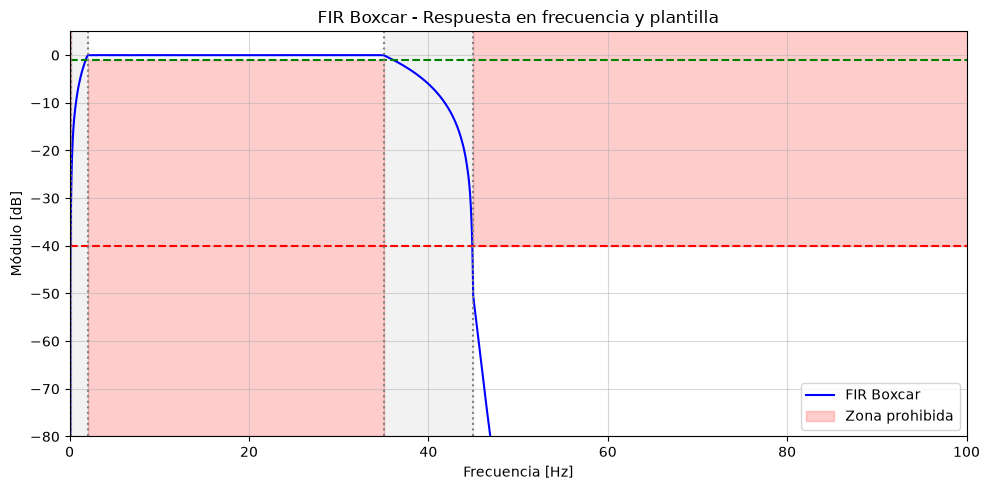

In [38]:
# 3.1. GRÁFICO INDIVIDUAL - FIR Boxcar
plt.figure(figsize=(10, 5))
plt.plot(w_boxcar, modulo_boxcar_db, color='blue', label='FIR Boxcar')

# Zonas prohibidas: rechazo > -40 dB y paso < -1 dB.
plt.fill_between([0, ws1], -atenuacion, 5,
                 color='red', alpha=0.20)
plt.fill_between([wp1, wp2], -80, -ripple,
                 color='red', alpha=0.20, label='Zona prohibida')
plt.fill_between([ws2, nyq_frec], -atenuacion, 5,
                 color='red', alpha=0.20)

# Transiciones: sin tolerancia fijada en la plantilla.
plt.fill_between([ws1, wp1], -80, 5, color='gray', alpha=0.10)
plt.fill_between([wp2, ws2], -80, 5, color='gray', alpha=0.10)

plt.axhline(-ripple, color='green', linestyle='--')
plt.axhline(-atenuacion, color='red', linestyle='--')
for frecuencia in [ws1, wp1, wp2, ws2]:
    plt.axvline(frecuencia, color='gray', linestyle=':')

plt.xlim(0, 100)
plt.ylim(-80, 5)
plt.title('FIR Boxcar - Respuesta en frecuencia y plantilla')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [39]:
# 3.1. VERIFICACIÓN NUMÉRICA - FIR Boxcar
rechazo_inf_boxcar = modulo_boxcar_db[w_boxcar <= ws1]
paso_boxcar = modulo_boxcar_db[(w_boxcar >= wp1) & (w_boxcar <= wp2)]
rechazo_sup_boxcar = modulo_boxcar_db[w_boxcar >= ws2]

print('\nFIR Boxcar:')
print('Rechazo inferior:', np.max(rechazo_inf_boxcar), 'dB')
print('Mínimo en paso:', np.min(paso_boxcar), 'dB')
print('Máximo en paso:', np.max(paso_boxcar), 'dB')
print('Rechazo superior:', np.max(rechazo_sup_boxcar), 'dB')


FIR Boxcar:
Rechazo inferior: -40.244274302472476 dB
Mínimo en paso: -0.13445841410640522 dB
Máximo en paso: 0.03856691219829505 dB
Rechazo superior: -50.50082151783062 dB


**Análisis del FIR Boxcar**

La respuesta en frecuencia presenta un comportamiento pasabanda y se aproxima a la plantilla establecida.

La verificación numérica muestra atenuaciones de **−40,24 dB** y **−50,50 dB** en las bandas de rechazo, cumpliendo el mínimo exigido de 40 dB.

En la banda de paso, la respuesta varía entre **−0,134 dB y +0,039 dB**, por lo que la pérdida se mantiene dentro de la tolerancia de 1 dB, aunque existe una pequeña ganancia por encima de 0 dB.

En consecuencia, el filtro satisface las condiciones principales de atenuación y presenta una leve desviación respecto de la ganancia ideal en la banda de paso.

### 3.2. Filtro FIR mediante cuadrados mínimos (FIRLS)

Como segundo diseño se utilizó el método de **cuadrados mínimos**, implementado mediante `firls` de SciPy. Este método busca minimizar el error cuadrático entre la respuesta deseada y la respuesta del filtro. Se seleccionaron **1851 coeficientes** y se asignaron distintos pesos a las bandas para priorizar la atenuación de las interferencias. Además, se incluyeron las regiones de transición dentro del diseño para obtener una respuesta más controlada.

In [40]:
# 3.2 FIR POR CUADRADOS MÍNIMOS (FIRLS)
ws1_ls, wp1_ls = ws1, wp1
wp2_ls, ws2_ls = wp2, ws2
numtaps_ls = 1851
gains_ls = [0, 0, 0, 1, 1, 1, 1, 0, 0, 0]
weight_ls = [20, 1, 1, 1, 10]  # mayor peso al rechazo inferior
b_ls = sig.firls(
    numtaps_ls,
    bands=[0, ws1_ls, ws1_ls, wp1_ls,
           wp1_ls, wp2_ls, wp2_ls, ws2_ls,
           ws2_ls, nyq_frec],
    desired=gains_ls, weight=weight_ls, fs=fs
)

w_ls, h_ls = sig.freqz(b_ls, worN=ww, fs=fs)
modulo_ls_db = 20 * np.log10(np.maximum(np.abs(h_ls), 1e-12))
print('FIRLS - coeficientes:', len(b_ls))

FIRLS - coeficientes: 1851


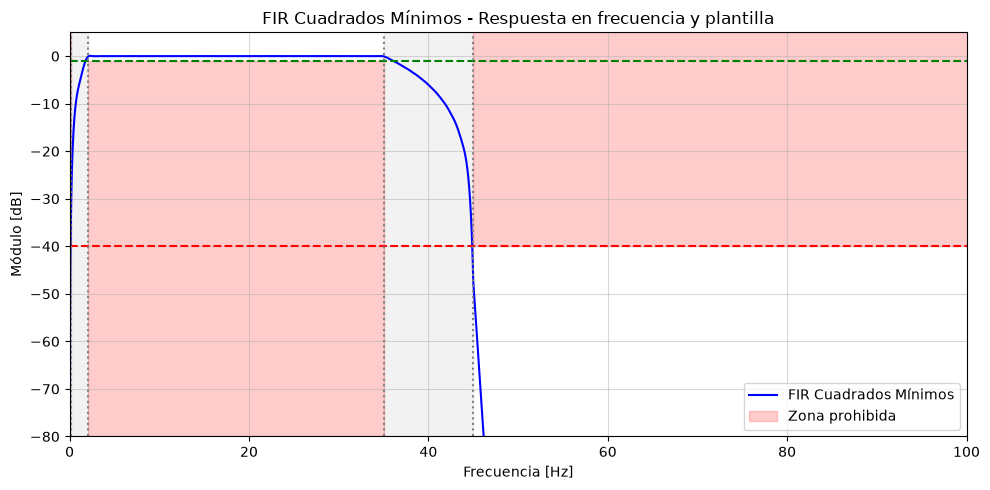

In [11]:
# 3.2. GRÁFICO INDIVIDUAL - FIR Cuadrados Mínimos
plt.figure(figsize=(10, 5))
plt.plot(w_ls, modulo_ls_db, color='blue', label='FIR Cuadrados Mínimos')

# Zonas prohibidas: rechazo > -40 dB y paso < -1 dB.
plt.fill_between([0, ws1], -atenuacion, 5,
                 color='red', alpha=0.20)
plt.fill_between([wp1, wp2], -80, -ripple,
                 color='red', alpha=0.20, label='Zona prohibida')
plt.fill_between([ws2, nyq_frec], -atenuacion, 5,
                 color='red', alpha=0.20)

# Transiciones: sin tolerancia fijada en la plantilla.
plt.fill_between([ws1, wp1], -80, 5, color='gray', alpha=0.10)
plt.fill_between([wp2, ws2], -80, 5, color='gray', alpha=0.10)

plt.axhline(-ripple, color='green', linestyle='--')
plt.axhline(-atenuacion, color='red', linestyle='--')
for frecuencia in [ws1, wp1, wp2, ws2]:
    plt.axvline(frecuencia, color='gray', linestyle=':')

plt.xlim(0, 100)
plt.ylim(-80, 5)
plt.title('FIR Cuadrados Mínimos - Respuesta en frecuencia y plantilla')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [41]:
# 3.2. VERIFICACIÓN NUMÉRICA - FIR Cuadrados Mínimos
rechazo_inf_ls = modulo_ls_db[w_ls <= ws1]
paso_ls = modulo_ls_db[(w_ls >= wp1) & (w_ls <= wp2)]
rechazo_sup_ls = modulo_ls_db[w_ls >= ws2]

print('\nFIR Cuadrados Mínimos:')
print('Rechazo inferior:', np.max(rechazo_inf_ls), 'dB')
print('Mínimo en paso:', np.min(paso_ls), 'dB')
print('Máximo en paso:', np.max(paso_ls), 'dB')
print('Rechazo superior:', np.max(rechazo_sup_ls), 'dB')


FIR Cuadrados Mínimos:
Rechazo inferior: -41.180624536086 dB
Mínimo en paso: -0.22441757605907658 dB
Máximo en paso: 0.05913698381718548 dB
Rechazo superior: -47.19876120859105 dB


**Análisis del FIR por cuadrados mínimos**

La respuesta en frecuencia presenta un comportamiento pasabanda y se aproxima a la plantilla establecida.

La verificación numérica muestra atenuaciones de **−41,18 dB** y **−47,20 dB** en las bandas de rechazo, cumpliendo el mínimo exigido de 40 dB.

En la banda de paso, la respuesta varía entre **−0,224 dB y +0,059 dB**, manteniendo la pérdida dentro de la tolerancia de 1 dB, aunque presenta una pequeña ganancia superior a 0 dB.

Por lo tanto, el filtro cumple las condiciones de rechazo y pérdida máxima, con una leve desviación respecto de la ganancia ideal en la banda de paso.

### 3.3. Filtro FIR mediante el algoritmo de Remez

Como tercer diseño se utilizó el **algoritmo de Remez**, que busca minimizar el máximo error ponderado entre la respuesta deseada y la obtenida.

Se seleccionaron **601 coeficientes** y se asignaron distintos pesos a las bandas. Además, se dividió la transición superior en regiones para controlar mejor la respuesta y evitar ganancias excesivas.

In [13]:
# 3.3. FIR POR PARKS-MCCLELLAN (REMEZ)
ws1_remez, wp1_remez = ws1, wp1
wp2_remez, ws2_remez = wp2, ws2

numtaps_remez = 601
gains_remez = [0, 0.948, 0.474, 0]
weight_remez = [40, 1, 1, 45]

b_remez = sig.remez(
    numtaps_remez,
    bands=[0, ws1_remez, wp1_remez, wp2_remez,
           38, 42, ws2_remez, nyq_frec],
    desired=gains_remez, weight=weight_remez, fs=fs,
    type='bandpass'
)

w_remez, h_remez = sig.freqz(b_remez, worN=ww, fs=fs)
modulo_remez_db = 20 * np.log10(np.maximum(np.abs(h_remez), 1e-12))

print('FIR Remez - coeficientes:', len(b_remez))


FIR Remez - coeficientes: 601


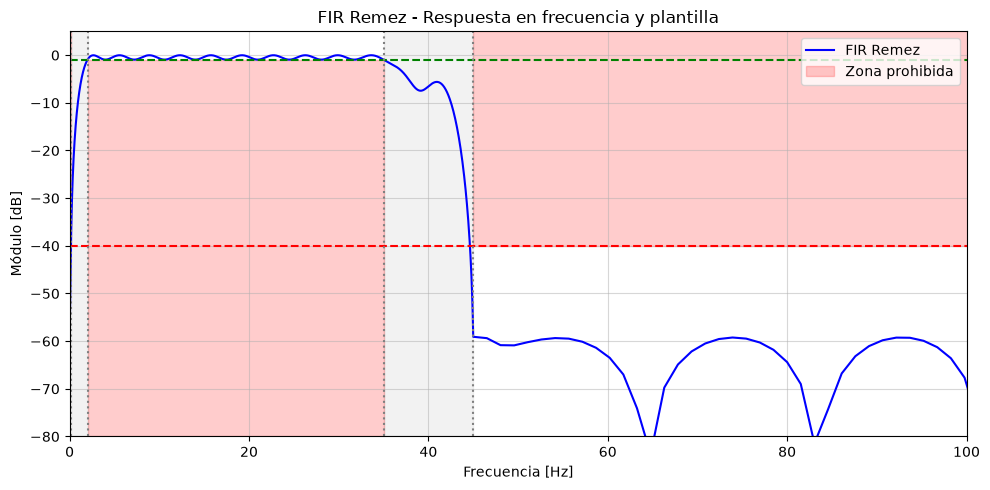

In [14]:
# 3.3. GRÁFICO INDIVIDUAL - FIR Remez
plt.figure(figsize=(10, 5))
plt.plot(w_remez, modulo_remez_db, color='blue', label='FIR Remez')

# Zonas prohibidas: rechazo > -40 dB y paso < -1 dB.
plt.fill_between([0, ws1], -atenuacion, 5,
                 color='red', alpha=0.20)
plt.fill_between([wp1, wp2], -80, -ripple,
                 color='red', alpha=0.20, label='Zona prohibida')
plt.fill_between([ws2, nyq_frec], -atenuacion, 5,
                 color='red', alpha=0.20)

# Transiciones: sin tolerancia fijada en la plantilla.
plt.fill_between([ws1, wp1], -80, 5, color='gray', alpha=0.10)
plt.fill_between([wp2, ws2], -80, 5, color='gray', alpha=0.10)

plt.axhline(-ripple, color='green', linestyle='--')
plt.axhline(-atenuacion, color='red', linestyle='--')
for frecuencia in [ws1, wp1, wp2, ws2]:
    plt.axvline(frecuencia, color='gray', linestyle=':')

plt.xlim(0, 100)
plt.ylim(-80, 5)
plt.title('FIR Remez - Respuesta en frecuencia y plantilla')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:

# 3.3. VERIFICACIÓN NUMÉRICA - FIR Remez

# Evaluamos la respuesta del filtro en cada banda.
rechazo_inf_remez = modulo_remez_db[w_remez <= ws1]
paso_remez = modulo_remez_db[(w_remez >= wp1) & (w_remez <= wp2)]
rechazo_sup_remez = modulo_remez_db[w_remez >= ws2]

print('\nFIR Remez:')
print('Rechazo inferior:', np.max(rechazo_inf_remez), 'dB')
print('Mínimo en paso:', np.min(paso_remez), 'dB')
print('Máximo en paso:', np.max(paso_remez), 'dB')
print('Rechazo superior:', np.max(rechazo_sup_remez), 'dB')


FIR Remez:
Rechazo inferior: -45.136142649317236 dB
Mínimo en paso: -0.9443748501717119 dB
Máximo en paso: -0.01334625158832558 dB
Rechazo superior: -59.055880836967205 dB


**Análisis del FIR Remez**

La respuesta en frecuencia presenta un comportamiento pasabanda y cumple las tolerancias establecidas en la plantilla.

Se obtuvieron atenuaciones de **−45,14 dB** y **−59,06 dB** en las bandas de rechazo, superando los 40 dB exigidos.

En la banda de paso, la respuesta varía entre **−0,944 dB y −0,013 dB**, manteniéndose dentro de los límites establecidos y sin presentar ganancias superiores a 0 dB.

Por lo tanto, el filtro Remez logra cumplir las especificaciones evaluadas utilizando solamente **601 coeficientes**, una cantidad menor que los otros dos diseños FIR.

### 3.4. Filtro IIR Butterworth

Como primer filtro IIR se utilizó una aproximación **Butterworth**, caracterizada por presentar una respuesta en magnitud máximamente plana en la banda de paso.

El diseño se realizó mediante `iirdesign` de SciPy, utilizando las frecuencias y tolerancias establecidas en la plantilla. Se empleó una representación en **secciones de segundo orden (SOS)** para mejorar la estabilidad numérica del filtrado.

In [16]:
# 3.4. IIR BUTTERWORTH
wp = [wp1, wp2]
ws = [ws1, ws2]

sos_butt = sig.iirdesign(
    wp=wp, ws=ws, gpass=ripple, gstop=atenuacion,
    fs=fs, ftype='butter', output='sos'
)

w_butt, h_butt = sig.sosfreqz(sos_butt, worN=ww, fs=fs)
modulo_butt_db = 20 * np.log10(np.maximum(np.abs(h_butt), 1e-12))

print('IIR Butterworth - secciones SOS:', len(sos_butt))


IIR Butterworth - secciones SOS: 20


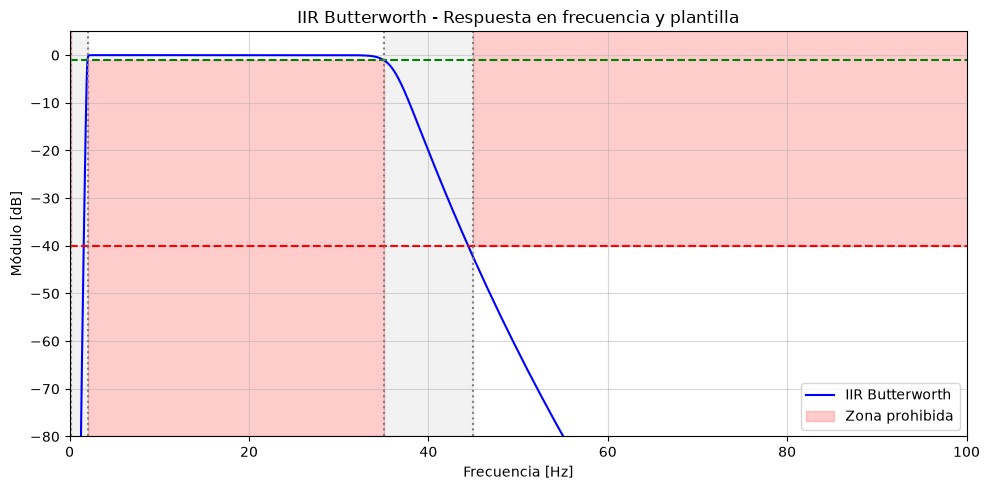

In [32]:
# 3.4. GRÁFICO INDIVIDUAL - IIR Butterworth
plt.figure(figsize=(10, 5))
plt.plot(w_butt, modulo_butt_db, color='blue', label='IIR Butterworth')

# Zonas prohibidas: rechazo > -40 dB y paso < -1 dB.
plt.fill_between([0, ws1], -atenuacion, 5,
                 color='red', alpha=0.20)
plt.fill_between([wp1, wp2], -80, -ripple,
                 color='red', alpha=0.20, label='Zona prohibida')
plt.fill_between([ws2, nyq_frec], -atenuacion, 5,
                 color='red', alpha=0.20)

# Transiciones: sin tolerancia fijada en la plantilla.
plt.fill_between([ws1, wp1], -80, 5, color='gray', alpha=0.10)
plt.fill_between([wp2, ws2], -80, 5, color='gray', alpha=0.10)

plt.axhline(-ripple, color='green', linestyle='--')
plt.axhline(-atenuacion, color='red', linestyle='--')
for frecuencia in [ws1, wp1, wp2, ws2]:
    plt.axvline(frecuencia, color='gray', linestyle=':')

plt.xlim(0, 100)
plt.ylim(-80, 5)
plt.title('IIR Butterworth - Respuesta en frecuencia y plantilla')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
# 3.4. VERIFICACIÓN NUMÉRICA - IIR Butterworth

# El máximo en rechazo es el peor caso.
# En paso calculamos el mínimo y máximo de ganancia.
rechazo_inf_butt = modulo_butt_db[w_butt <= ws1]
paso_butt = modulo_butt_db[(w_butt >= wp1) & (w_butt <= wp2)]
rechazo_sup_butt = modulo_butt_db[w_butt >= ws2]

print('\nIIR Butterworth:')
print('Rechazo inferior:', np.max(rechazo_inf_butt), 'dB')
print('Mínimo en paso:', np.min(paso_butt), 'dB')
print('Máximo en paso:', np.max(paso_butt), 'dB')
print('Rechazo superior:', np.max(rechazo_sup_butt), 'dB')



IIR Butterworth:
Rechazo inferior: -240.0 dB
Mínimo en paso: -1.0000000001116929 dB
Máximo en paso: 3.077747542246018e-11 dB
Rechazo superior: -42.37621749513447 dB


**Análisis del IIR Butterworth**

La respuesta en frecuencia presenta un comportamiento pasabanda, con una banda de paso suave y sin oscilaciones apreciables.

Se obtuvieron atenuaciones de **−240 dB** y **−42,38 dB** en las bandas de rechazo, cumpliendo el mínimo exigido de 40 dB. El valor de −240 dB corresponde al límite numérico utilizado en el cálculo.

En la banda de paso, la respuesta varía aproximadamente entre **−1 dB y 0 dB**, respetando la tolerancia establecida.

Por lo tanto, el filtro Butterworth cumple las especificaciones evaluadas de la plantilla, utilizando **20 secciones de segundo orden (SOS)**.

### 3.5. Filtro IIR Chebyshev tipo I

Como segundo filtro IIR se utilizó una aproximación **Chebyshev tipo I**, que, a diferencia de Butterworth, permite oscilaciones controladas en la banda de paso.

El diseño se realizó mediante `iirdesign`, utilizando las mismas especificaciones de la plantilla y una representación en secciones de segundo orden (SOS).

In [43]:
# 3.5. IIR CHEBYSHEV TIPO I

sos_cheby1 = sig.iirdesign(
    wp=wp, ws=ws, gpass=ripple, gstop=atenuacion,
    fs=fs, ftype='cheby1', output='sos'
)

w_cheby1, h_cheby1 = sig.sosfreqz(sos_cheby1, worN=ww, fs=fs)
modulo_cheby1_db = 20 * np.log10(np.maximum(np.abs(h_cheby1), 1e-12))

print('IIR Chebyshev I - secciones SOS:', len(sos_cheby1))


IIR Chebyshev I - secciones SOS: 8


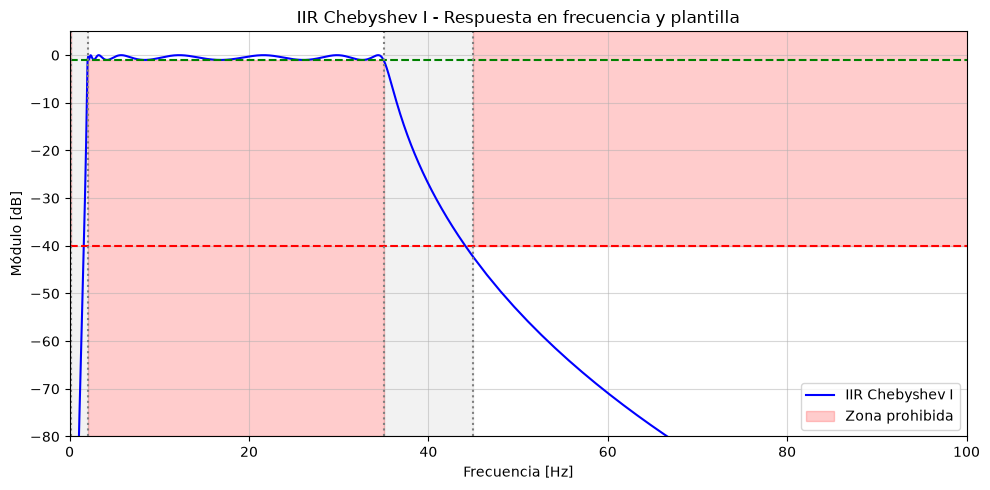

In [20]:
# 3.5. GRÁFICO INDIVIDUAL - IIR Chebyshev I
plt.figure(figsize=(10, 5))
plt.plot(w_cheby1, modulo_cheby1_db, color='blue', label='IIR Chebyshev I')

# Zonas prohibidas: rechazo > -40 dB y paso < -1 dB.
plt.fill_between([0, ws1], -atenuacion, 5,
                 color='red', alpha=0.20)
plt.fill_between([wp1, wp2], -80, -ripple,
                 color='red', alpha=0.20, label='Zona prohibida')
plt.fill_between([ws2, nyq_frec], -atenuacion, 5,
                 color='red', alpha=0.20)

# Transiciones: sin tolerancia fijada en la plantilla.
plt.fill_between([ws1, wp1], -80, 5, color='gray', alpha=0.10)
plt.fill_between([wp2, ws2], -80, 5, color='gray', alpha=0.10)

plt.axhline(-ripple, color='green', linestyle='--')
plt.axhline(-atenuacion, color='red', linestyle='--')
for frecuencia in [ws1, wp1, wp2, ws2]:
    plt.axvline(frecuencia, color='gray', linestyle=':')

plt.xlim(0, 100)
plt.ylim(-80, 5)
plt.title('IIR Chebyshev I - Respuesta en frecuencia y plantilla')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
# 3.5. VERIFICACIÓN NUMÉRICA - IIR Chebyshev I
rechazo_inf_cheby1 = modulo_cheby1_db[w_cheby1 <= ws1]
paso_cheby1 = modulo_cheby1_db[(w_cheby1 >= wp1) & (w_cheby1 <= wp2)]
rechazo_sup_cheby1 = modulo_cheby1_db[w_cheby1 >= ws2]

print('\nIIR Chebyshev I:')
print('Rechazo inferior:', np.max(rechazo_inf_cheby1), 'dB')
print('Mínimo en paso:', np.min(paso_cheby1), 'dB')
print('Máximo en paso:', np.max(paso_cheby1), 'dB')
print('Rechazo superior:', np.max(rechazo_sup_cheby1), 'dB')



IIR Chebyshev I:
Rechazo inferior: -240.0 dB
Mínimo en paso: -1.0000000000426064 dB
Máximo en paso: -2.6206889761955795e-07 dB
Rechazo superior: -42.3252689683416 dB


**Análisis del IIR Chebyshev tipo I**

La respuesta en frecuencia presenta un comportamiento pasabanda, con las oscilaciones características de Chebyshev tipo I en la banda de paso.

Se obtuvieron atenuaciones de **−240 dB** y **−42,33 dB** en las bandas de rechazo, cumpliendo el mínimo exigido de 40 dB. El valor de −240 dB corresponde al límite numérico utilizado en el cálculo.

En la banda de paso, la respuesta oscila aproximadamente entre **−1 dB y 0 dB**, respetando la tolerancia establecida.

Por lo tanto, el filtro cumple las especificaciones evaluadas utilizando **8 secciones de segundo orden (SOS)**, frente a las 20 del Butterworth.

### 3.6. Filtro IIR Cauer (elíptico)

Como tercer filtro IIR se utilizó una aproximación **Cauer o elíptica**, que permite oscilaciones controladas tanto en la banda de paso como en las bandas de rechazo.

El diseño se realizó mediante `iirdesign`, utilizando las especificaciones de la plantilla y una representación en secciones de segundo orden (SOS). Este método permite obtener transiciones pronunciadas con un orden relativamente bajo.

In [22]:
# 3.6. IIR CAUER (ELÍPTICO)
sos_cauer = sig.iirdesign(
    wp=wp, ws=ws, gpass=ripple, gstop=atenuacion,
    fs=fs, ftype='ellip', output='sos'
)

w_cauer, h_cauer = sig.sosfreqz(sos_cauer, worN=ww, fs=fs)
modulo_cauer_db = 20 * np.log10(np.maximum(np.abs(h_cauer), 1e-12))

print('IIR Cauer - secciones SOS:', len(sos_cauer))


IIR Cauer - secciones SOS: 5


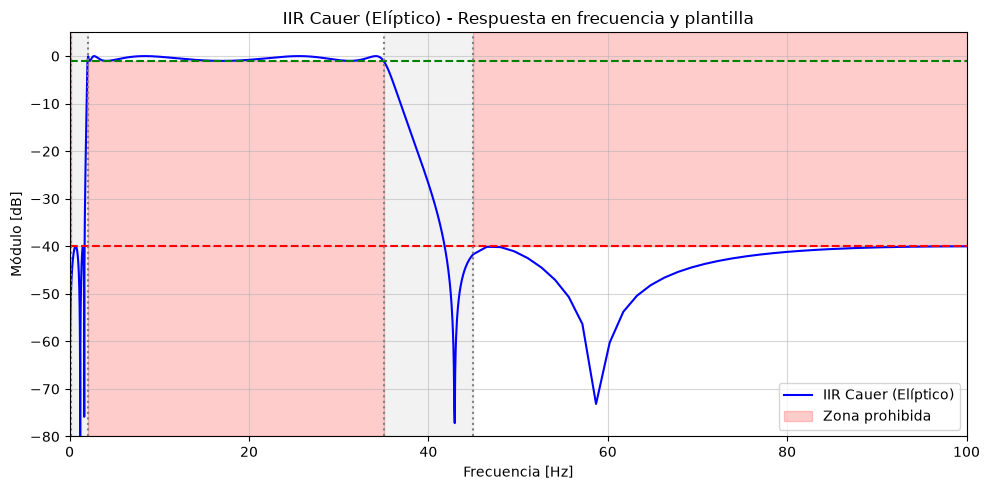

In [23]:
# 3.6. GRÁFICO INDIVIDUAL - IIR Cauer (Elíptico)
plt.figure(figsize=(10, 5))
plt.plot(w_cauer, modulo_cauer_db, color='blue', label='IIR Cauer (Elíptico)')

# Zonas prohibidas: rechazo > -40 dB y paso < -1 dB.
plt.fill_between([0, ws1], -atenuacion, 5,
                 color='red', alpha=0.20)
plt.fill_between([wp1, wp2], -80, -ripple,
                 color='red', alpha=0.20, label='Zona prohibida')
plt.fill_between([ws2, nyq_frec], -atenuacion, 5,
                 color='red', alpha=0.20)

# Transiciones: sin tolerancia fijada en la plantilla.
plt.fill_between([ws1, wp1], -80, 5, color='gray', alpha=0.10)
plt.fill_between([wp2, ws2], -80, 5, color='gray', alpha=0.10)

plt.axhline(-ripple, color='green', linestyle='--')
plt.axhline(-atenuacion, color='red', linestyle='--')
for frecuencia in [ws1, wp1, wp2, ws2]:
    plt.axvline(frecuencia, color='gray', linestyle=':')

plt.xlim(0, 100)
plt.ylim(-80, 5)
plt.title('IIR Cauer (Elíptico) - Respuesta en frecuencia y plantilla')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
# 3.6. VERIFICACIÓN NUMÉRICA - IIR Cauer (Elíptico)
rechazo_inf_cauer = modulo_cauer_db[w_cauer <= ws1]
paso_cauer = modulo_cauer_db[(w_cauer >= wp1) & (w_cauer <= wp2)]
rechazo_sup_cauer = modulo_cauer_db[w_cauer >= ws2]

print('\nIIR Cauer (Elíptico):')
print('Rechazo inferior:', np.max(rechazo_inf_cauer), 'dB')
print('Mínimo en paso:', np.min(paso_cauer), 'dB')
print('Máximo en paso:', np.max(paso_cauer), 'dB')
print('Rechazo superior:', np.max(rechazo_sup_cauer), 'dB')



IIR Cauer (Elíptico):
Rechazo inferior: -53.15489990264929 dB
Mínimo en paso: -0.99999999999994 dB
Máximo en paso: -4.591046430170679e-05 dB
Rechazo superior: -40.00034872314934 dB


**Análisis del IIR Cauer (elíptico)**

La respuesta en frecuencia presenta un comportamiento pasabanda, con oscilaciones características tanto en la banda de paso como en las de rechazo.

Se obtuvieron atenuaciones de **−53,15 dB** y **−40,00 dB** en las bandas de rechazo, cumpliendo el mínimo exigido de 40 dB.

En la banda de paso, la respuesta varía aproximadamente entre **−1 dB y 0 dB**, respetando la tolerancia establecida.

Por lo tanto, el filtro Cauer cumple las especificaciones evaluadas utilizando solamente **5 secciones de segundo orden (SOS)**, una cantidad menor que Butterworth y Chebyshev tipo I.

## 4. Aplicación de los filtros al ECG

En esta sección se aplican los seis filtros diseñados al registro electrocardiográfico original, con el objetivo de evaluar su capacidad para reducir las interferencias y conservar la morfología de la señal.

### 4.1. Aplicación de los filtros IIR
Los filtros Butterworth, Chebyshev tipo I y Cauer se aplicaron mediante `sosfiltfilt`, que realiza un filtrado hacia adelante y hacia atrás, evitando un desplazamiento temporal neto de los latidos.

In [45]:
# 4.1. APLICACIÓN DE LOS FILTROS IIR
# Aplicamos los tres filtros IIR al ECG original.
# Utilizamos sosfiltfilt para filtrar hacia adelante y hacia atrás,
# evitando un desplazamiento temporal de los latidos.

# Filtro Butterworth
ecg_filt_butt = sig.sosfiltfilt(sos_butt, ecg_conruido)

# Filtro Chebyshev tipo I
ecg_filt_cheby1 = sig.sosfiltfilt(sos_cheby1, ecg_conruido)

# Filtro Cauer (elíptico)
ecg_filt_cauer = sig.sosfiltfilt(sos_cauer, ecg_conruido)

# Verificamos que las señales filtradas tengan la misma longitud
# que el registro original.
print("ECG original:", len(ecg_conruido))
print("ECG Butterworth:", len(ecg_filt_butt))
print("ECG Chebyshev I:", len(ecg_filt_cheby1))
print("ECG Cauer:", len(ecg_filt_cauer))


ECG original: 1129116
ECG Butterworth: 1129116
ECG Chebyshev I: 1129116
ECG Cauer: 1129116


### 4.2. Evaluación de los filtros IIR en regiones con interferencias

Se compararon las señales filtradas con el ECG original en dos regiones indicadas: **muestras 4000 a 5500 y 10000 a 11000**.
El objetivo es observar la reducción de las interferencias y evaluar si los filtros conservan las características principales de los latidos.

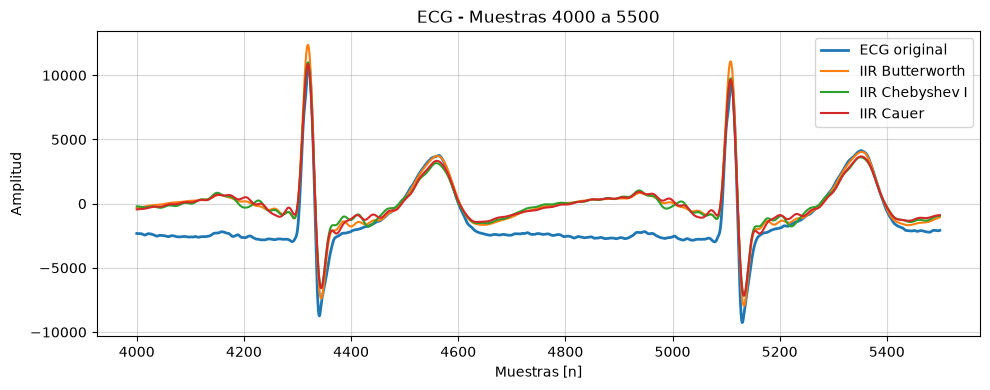

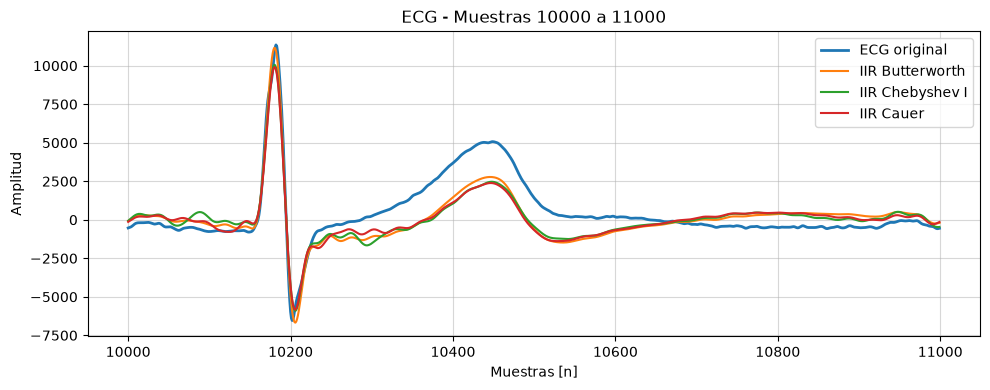

In [53]:
# 4.2. REGIONES DE INTERÉS CON RUIDO
# Cantidad total de muestras del ECG.
cant_muestras = ecg_conruido.shape[0]

# Regiones de interés, Los límites están expresados en número de muestras.
regs_interes = (
    [4000, 5500],
    [10000, 11000]
)

# Recorremos cada región y comparamos el ECG original
# con los tres filtros IIR.
for ii in regs_interes:
    # Seleccionamos las muestras de la región,

    zoom_region = np.arange(
        np.max([0, ii[0]]),
        np.min([cant_muestras, ii[1]]),
        dtype='uint'
    )

    # Creamos un gráfico para cada región.
    plt.figure(figsize=(10, 4))

    # ECG original sin filtrar.
    plt.plot(
        zoom_region,
        ecg_conruido[zoom_region],
        label='ECG original',
        linewidth=2
    )

    # ECG filtrado con Butterworth.
    plt.plot(
        zoom_region,
        ecg_filt_butt[zoom_region],
        label='IIR Butterworth',
        linewidth=1.5
    )

    # ECG filtrado con Chebyshev tipo I.
    plt.plot(
        zoom_region,
        ecg_filt_cheby1[zoom_region],
        label='IIR Chebyshev I',
        linewidth=1.5
    )

    # ECG filtrado con Cauer.
    plt.plot(
        zoom_region,
        ecg_filt_cauer[zoom_region],
        label='IIR Cauer',
        linewidth=1.5
    )

    # Configuración del gráfico.
    plt.title(
        'ECG - Muestras ' + str(ii[0]) +
        ' a ' + str(ii[1])
    )

    plt.xlabel('Muestras [n]')
    plt.ylabel('Amplitud')
    plt.grid(True, alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


**Análisis de los filtros IIR en regiones con interferencias**

En ambas regiones, los tres filtros IIR reducen las variaciones de la línea de base y conservan la ubicación temporal de los complejos QRS.

En la región de **4000 a 5500 muestras**, se observa una corrección del desplazamiento de la línea de base, con pequeñas modificaciones en la amplitud de los latidos.

En la región de **10000 a 11000 muestras**, los filtros también atenúan considerablemente la onda posterior al QRS, evidenciando una posible pérdida de componentes útiles del ECG.

Por lo tanto, aunque los tres filtros reducen las interferencias, también introducen modificaciones en la morfología de la señal, posiblemente asociadas al límite inferior de paso de **2 Hz**.

### 4.3. Evaluación de los filtros IIR en regiones de menor ruido

Se analizaron tres regiones propuestas: **5 a 5,2 minutos, 12 a 12,4 minutos y 15 a 15,2 minutos**.
El objetivo es comprobar si los filtros conservan la morfología del ECG en regiones donde se espera una menor presencia de interferencias, evitando modificaciones innecesarias de la señal.

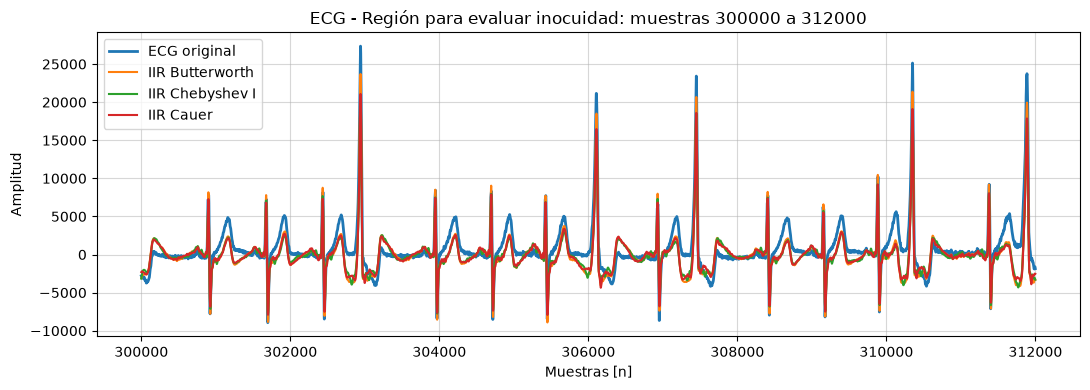

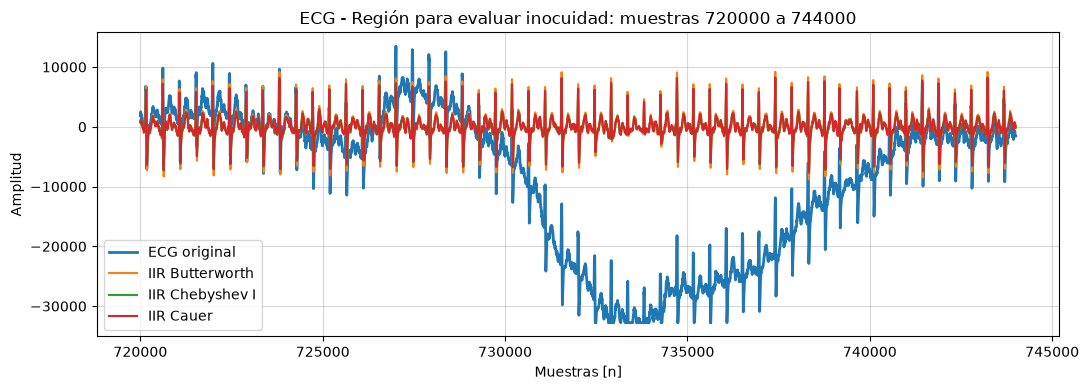

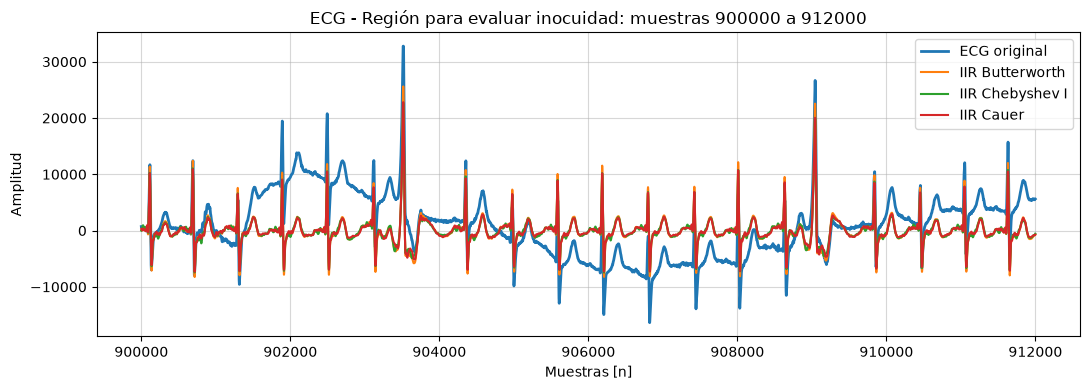

In [54]:
# 4.3. REGIONES INDICADAS COMO SIN RUIDO
# Convertimos los tiempos de minutos a números de muestras.
regs_interes = (
    np.array([5, 5.2]) * 60 * fs,
    np.array([12, 12.4]) * 60 * fs,
    np.array([15, 15.2]) * 60 * fs
)

for ii in regs_interes:

    # Seleccionamos las muestras dentro de los límites del registro.
    zoom_region = np.arange(
        np.max([0, ii[0]]),
        np.min([cant_muestras, ii[1]]),
        dtype='uint'
    )

    plt.figure(figsize=(11, 4))

    plt.plot(zoom_region, ecg_conruido[zoom_region],
             label='ECG original', linewidth=2)

    # Los tres IIR aplicados al mismo registro.
    plt.plot(zoom_region, ecg_filt_butt[zoom_region],
             label='IIR Butterworth', linewidth=1.5)

    plt.plot(zoom_region, ecg_filt_cheby1[zoom_region],
             label='IIR Chebyshev I', linewidth=1.5)

    plt.plot(zoom_region, ecg_filt_cauer[zoom_region],
             label='IIR Cauer', linewidth=1.5)

    plt.title('ECG - Región para evaluar inocuidad: muestras ' +
              str(int(ii[0])) + ' a ' + str(int(ii[1])))

    plt.xlabel('Muestras [n]')
    plt.ylabel('Amplitud')
    plt.grid(True, alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


**Análisis de los filtros IIR en regiones de menor ruido**

En las tres regiones analizadas, los filtros IIR conservan la ubicación temporal de los complejos QRS, aunque producen modificaciones en su amplitud y en las ondas de menor frecuencia.

En particular, la región de **720000 a 744000 muestras** presenta un desplazamiento considerable de la línea de base, a pesar de haber sido propuesta para evaluar la inocuidad. Los filtros consiguen corregirlo eficazmente.

Se observa un comportamiento similar en la región de **900000 a 912000 muestras**, mientras que en la primera región también aparecen cambios en la amplitud de los latidos.

Por lo tanto, los filtros permiten reducir la deriva de la línea de base, pero **no resultan completamente inocuos**, ya que también atenúan componentes útiles del ECG, posiblemente debido al límite inferior de paso establecido en 2 Hz.

### 4.4. Aplicación de los filtros FIR

Se aplicaron los tres filtros FIR diseñados al registro ECG original mediante `fftconvolve`, que permite calcular la convolución de manera eficiente.

Como los filtros tienen coeficientes simétricos y una cantidad impar de coeficientes, se utilizó `mode='same'` para compensar su retardo de grupo y conservar la alineación temporal de los latidos.

In [48]:
# 4.4. APLICACIÓN DE LOS FILTROS FIR
ecg_filt_boxcar = sig.fftconvolve(
    ecg_conruido, b_fir_boxcar, mode='same'
)

ecg_filt_ls = sig.fftconvolve(
    ecg_conruido, b_ls, mode='same'
)

ecg_filt_remez = sig.fftconvolve(
    ecg_conruido, b_remez, mode='same'
)

print("FIR Boxcar:", len(ecg_filt_boxcar))
print("FIR Cuadrados Mínimos:", len(ecg_filt_ls))
print("FIR Remez:", len(ecg_filt_remez))


FIR Boxcar: 1129116
FIR Cuadrados Mínimos: 1129116
FIR Remez: 1129116


### 4.5. Evaluación de los filtros FIR sobre el ECG

Se compararon los resultados de los tres filtros FIR con el ECG original en las mismas regiones utilizadas para evaluar los IIR.
El objetivo es analizar la reducción de interferencias y la conservación de los complejos QRS y de las demás componentes del ECG, tanto en regiones con ruido como en aquellas propuestas para evaluar la inocuidad del filtrado.

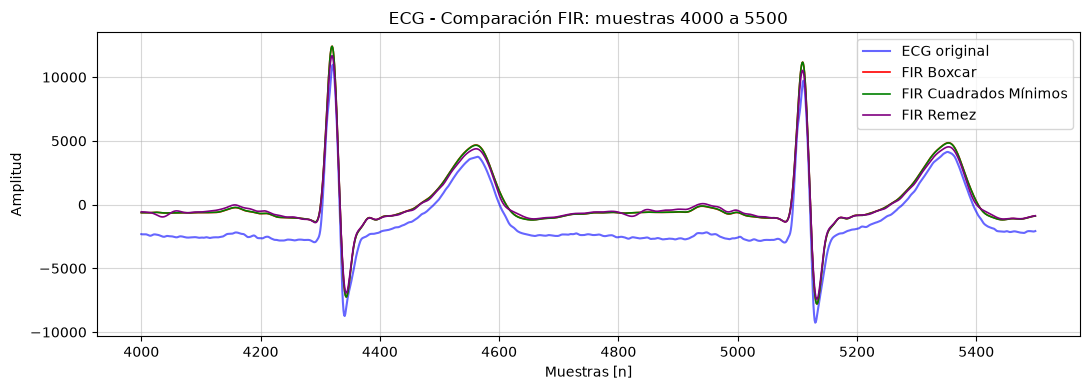

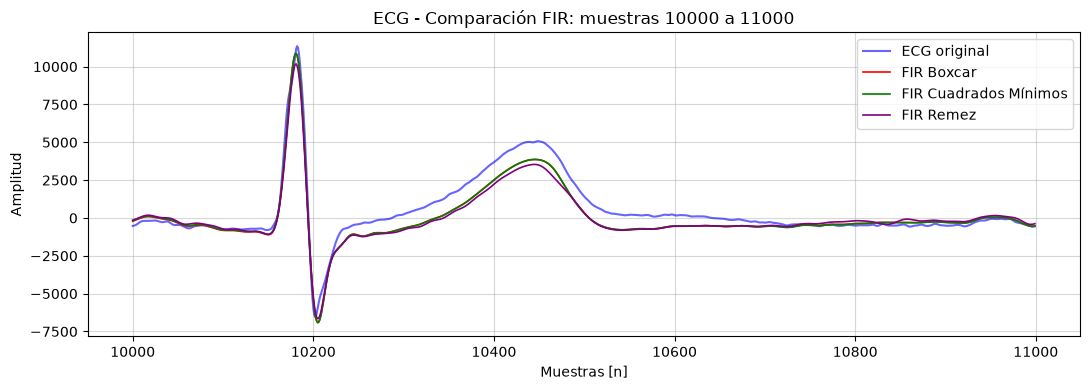

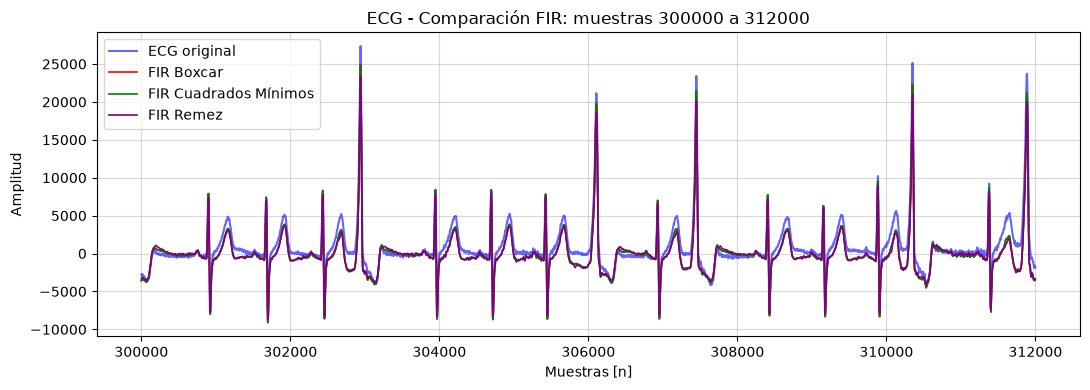

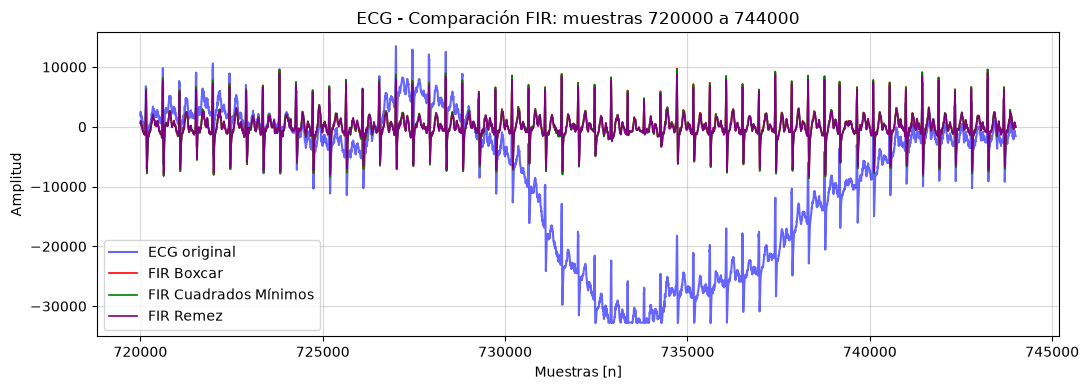

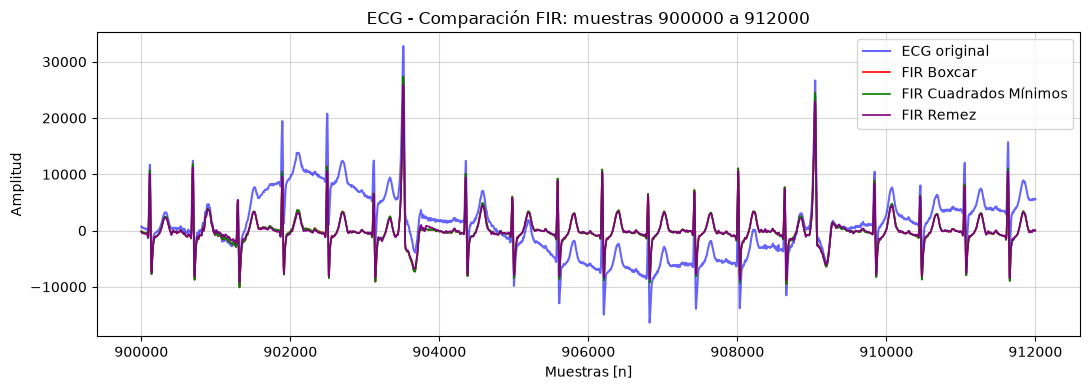

In [55]:
# 4.5. COMPARACIÓN DE LOS FILTROS FIR
regs_fir = (
    [4000, 5500],
    [10000, 11000],
    [300000, 312000],
    [720000, 744000],
    [900000, 912000]
)

for ii in regs_fir:

    # Seleccionamos las muestras de cada región.
    zoom_region = np.arange(
        np.max([0, ii[0]]),
        np.min([cant_muestras, ii[1]]),
        dtype='uint'
    )

    plt.figure(figsize=(11, 4))

    # ECG original.
    plt.plot(zoom_region, ecg_conruido[zoom_region],
             label='ECG original', color='blue',
             linewidth=1.5, alpha=0.6)

    # ECG filtrado mediante ventana rectangular.
    plt.plot(zoom_region, ecg_filt_boxcar[zoom_region],
             label='FIR Boxcar', color='red',
             linewidth=1.2)

    # ECG filtrado mediante cuadrados mínimos.
    plt.plot(zoom_region, ecg_filt_ls[zoom_region],
             label='FIR Cuadrados Mínimos', color='green',
             linewidth=1.2)

    # ECG filtrado mediante Parks-McClellan-Remez.
    plt.plot(zoom_region, ecg_filt_remez[zoom_region],
             label='FIR Remez', color='purple',
             linewidth=1.2)

    plt.title('ECG - Comparación FIR: muestras ' +
              str(ii[0]) + ' a ' + str(ii[1]))
    plt.xlabel('Muestras [n]')
    plt.ylabel('Amplitud')
    plt.grid(True, alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


**Análisis de los filtros FIR**

Los tres filtros FIR presentan resultados similares, reduciendo considerablemente los desplazamientos de la línea de base y conservando la ubicación temporal de los complejos QRS.

En las regiones de **4000 a 5500** y **10000 a 11000 muestras**, se observa una reducción de las interferencias, aunque también se modifica la amplitud de algunas ondas.

En las regiones restantes, especialmente entre **720000 y 744000 muestras**, los filtros corrigen importantes desplazamientos de la línea de base. Sin embargo, también atenúan componentes útiles del ECG, por lo que no resultan completamente inofensicos.

En general, los tres diseños presentan un comportamiento semejante, evidenciando un compromiso entre la eliminación de interferencias y la conservación de la morfología de la señal.

### 4.6. Prueba complementaria: modificación de la frecuencia inferior de paso

Debido a las alteraciones observadas en algunas ondas del ECG, se realizó una prueba adicional con un filtro Butterworth cuya frecuencia inferior de paso se redujo de **2 Hz a 0,5 Hz**.
El objetivo es evaluar si esta modificación permite conservar mejor las componentes lentas del ECG, manteniendo la reducción del desplazamiento de la línea de base. Esta prueba no modifica la plantilla ni los seis filtros originales.

In [52]:
# 4.6. PRUEBA DE FRECUENCIA INFERIOR DE PASO
# Comparamos el Butterworth original de 2 Hz con otro
# cuya frecuencia inferior de paso sea 0.5 Hz.
wp_prueba = [0.5, wp2]
# Diseñamos el Butterworth de prueba.
# Conservamos las frecuencias de rechazo y tolerancias.
sos_butt_05 = sig.iirdesign(
    wp=wp_prueba,
    ws=ws,
    gpass=ripple,
    gstop=atenuacion,
    fs=fs,
    ftype='butter',
    output='sos'
)

# Aplicamos el nuevo filtro al ECG original.
ecg_filt_butt_05 = sig.sosfiltfilt(
    sos_butt_05, ecg_conruido
)

print("Secciones SOS del Butterworth 0.5 Hz:", len(sos_butt_05))


Secciones SOS del Butterworth 0.5 Hz: 21


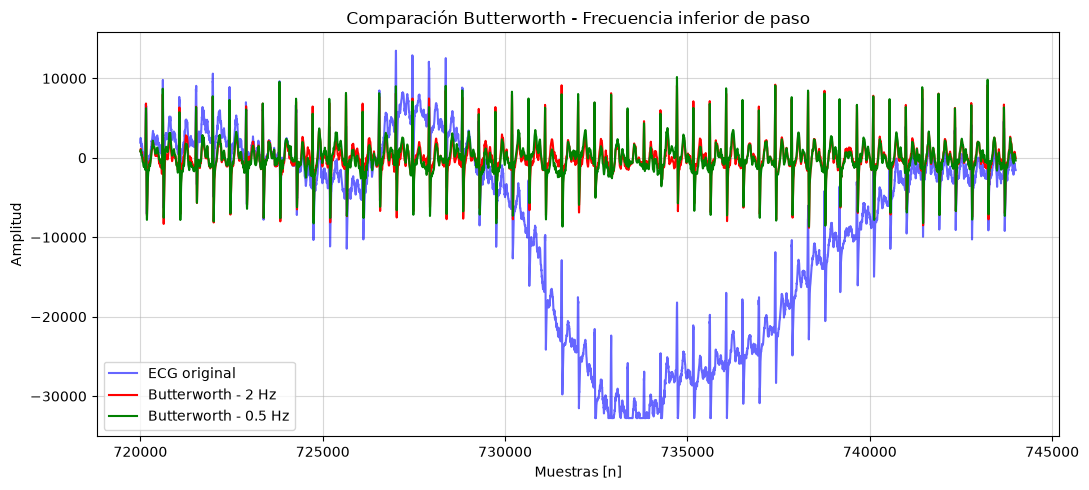

In [56]:
# COMPARACIÓN DE LOS DOS BUTTERWORTH
# Evaluamos si el filtro de 0.5 Hz consigue reducirlo.
zoom_region = np.arange(720000, 744000)

plt.figure(figsize=(11, 5))

# ECG original.
plt.plot(
    zoom_region, ecg_conruido[zoom_region],
    label='ECG original', color='blue', alpha=0.6
)

# Butterworth que diseñamos inicialmente.
plt.plot(
    zoom_region, ecg_filt_butt[zoom_region],
    label='Butterworth - 2 Hz', color='red'
)

# Butterworth de prueba.
plt.plot(
    zoom_region, ecg_filt_butt_05[zoom_region],
    label='Butterworth - 0.5 Hz', color='green'
)

plt.title('Comparación Butterworth - Frecuencia inferior de paso')
plt.xlabel('Muestras [n]')
plt.ylabel('Amplitud')
plt.grid(True, alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


**Análisis de la prueba complementaria**

Ambos filtros Butterworth reducen considerablemente el desplazamiento de la línea de base, manteniendo los latidos centrados aproximadamente alrededor de cero.

El filtro con frecuencia inferior de paso de **0,5 Hz** presenta amplitudes ligeramente mayores en algunos latidos respecto del filtro original de 2 Hz, lo que sugiere una mejor conservación de ciertas componentes del ECG.

Por lo tanto, la prueba evidencia que la elección de la frecuencia inferior de paso influye tanto en la eliminación de interferencias como en la conservación de la señal, siendo necesario considerar este compromiso durante el diseño.

## 5. Conclusiones

En este trabajo se diseñaron y aplicaron **tres filtros FIR y tres filtros IIR** para reducir las interferencias presentes en un registro ECG. Los seis diseños cumplieron las tolerancias principales de la plantilla en las frecuencias evaluadas.

Los filtros FIR presentaron resultados similares, destacándose **Remez** por utilizar una menor cantidad de coeficientes. Entre los IIR, **Cauer** requirió menos secciones SOS que Butterworth y Chebyshev tipo I.

Al aplicar los filtros al ECG, se observó una reducción importante de los desplazamientos de la línea de base y una conservación general de la ubicación de los complejos QRS. Sin embargo, también se modificó la amplitud de algunas ondas, evidenciando que el filtrado no resulta completamente inocuo.

La prueba complementaria con Butterworth de **0,5 Hz** sugirió una mejor conservación de ciertas componentes respecto del diseño original de 2 Hz.

En conclusión, el trabajo permitió comprobar que el diseño de filtros requiere encontrar un **equilibrio entre la reducción de interferencias y la conservación de la información útil de la señal**.